from pathlib import Path
import pandas as pd

# =========
# Config
# =========
INPUT_CSV = Path("./metrics/degradation_horizon_stress.csv")
OUTPUT_CSV = Path("./metrics/degradation_horizon_stress_selected_links.csv")

# Pares (link, protocol) escolhidos
SELECTED = [
    ("ac-pa", "bbr"), ("ac-to", "bbr"), ("ce-pi", "bbr"),
    ("es-ce", "bbr"), ("es-pr", "bbr"), ("go-sp", "bbr"),
    ("ma-es", "bbr"), ("ma-pa", "bbr"), ("ms-to", "bbr"),
    ("mt-ma", "bbr"), ("rs-ac", "bbr"), ("rs-to", "bbr"),
    ("sc-to", "bbr"),
]

# =========
# Load
# =========
df = pd.read_csv(INPUT_CSV)

required_cols = {"link", "protocol", "model", "stress_rate", "horizon", "rmse"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"CSV não tem as colunas esperadas. Faltando: {sorted(missing)}")

# =========
# Filter
# =========
selected_set = set(SELECTED)

# (link, protocol) por linha
lp = list(zip(df["link"].astype(str), df["protocol"].astype(str)))
mask = [pair in selected_set for pair in lp]

df_sel = df.loc[mask].copy()

# (Opcional) ordenar para ficar organizado
df_sel = df_sel.sort_values(["link", "protocol", "model", "stress_rate", "horizon"], kind="mergesort")

# =========
# Save
# =========
df_sel.to_csv(OUTPUT_CSV, index=False)

print(f"Linhas antes: {len(df)}")
print(f"Linhas depois: {len(df_sel)}")
print(f"Salvo em: {OUTPUT_CSV.resolve()}")


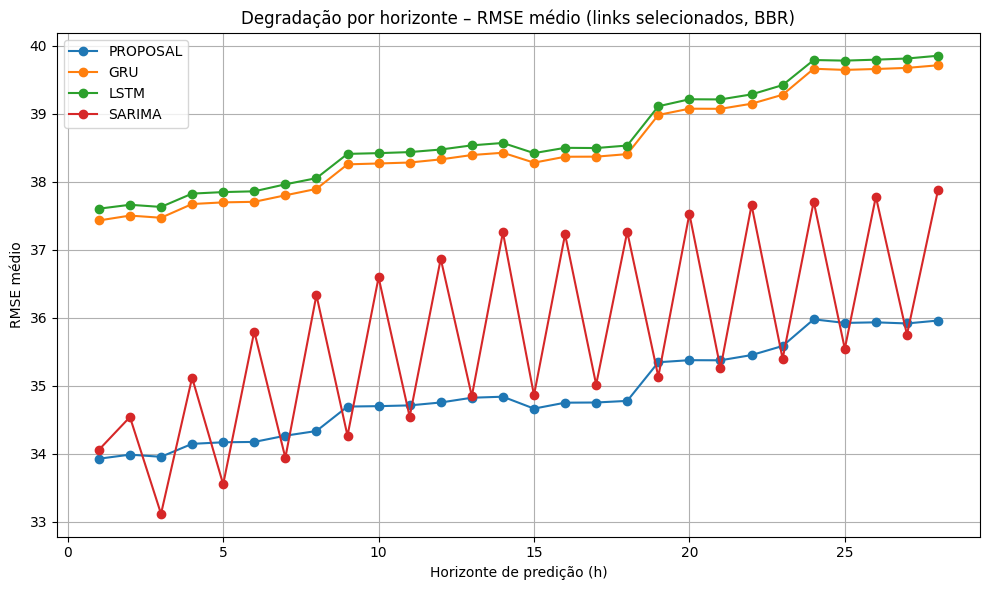

,model,horizon,mean_rmse
0,GRU,1,37.431279
1,GRU,2,37.503177
2,GRU,3,37.471324
3,GRU,4,37.673347
4,GRU,5,37.697646


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# Config
# =========================
CSV_PATH = Path("./metrics/degradation_horizon_stress_selected_links.csv")
MODELS = ["PROPOSAL", "GRU", "LSTM", "SARIMA"]  # SARIMA se existir
OUTPUT_FIG = Path("./metrics/degradation_horizon_mean_rmse.png")

# =========================
# Load data
# =========================
df = pd.read_csv(CSV_PATH)

# Garantir tipos corretos
df["horizon"] = df["horizon"].astype(int)
df["rmse"] = df["rmse"].astype(float)

# =========================
# Agregação: RMSE médio por horizonte e modelo
# =========================
df_mean = (
    df.groupby(["model", "horizon"], as_index=False)
      .agg(mean_rmse=("rmse", "mean"))
)

# =========================
# Plot
# =========================
plt.figure(figsize=(10, 6))

for model in MODELS:
    if model in df_mean["model"].values:
        g = df_mean[df_mean["model"] == model]
        plt.plot(g["horizon"], g["mean_rmse"], marker="o", label=model)

plt.xlabel("Horizonte de predição (h)")
plt.ylabel("RMSE médio")
plt.title("Degradação por horizonte – RMSE médio (links selecionados, BBR)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Salvar figura
plt.savefig(OUTPUT_FIG, dpi=150)
plt.show()

df_mean.head()


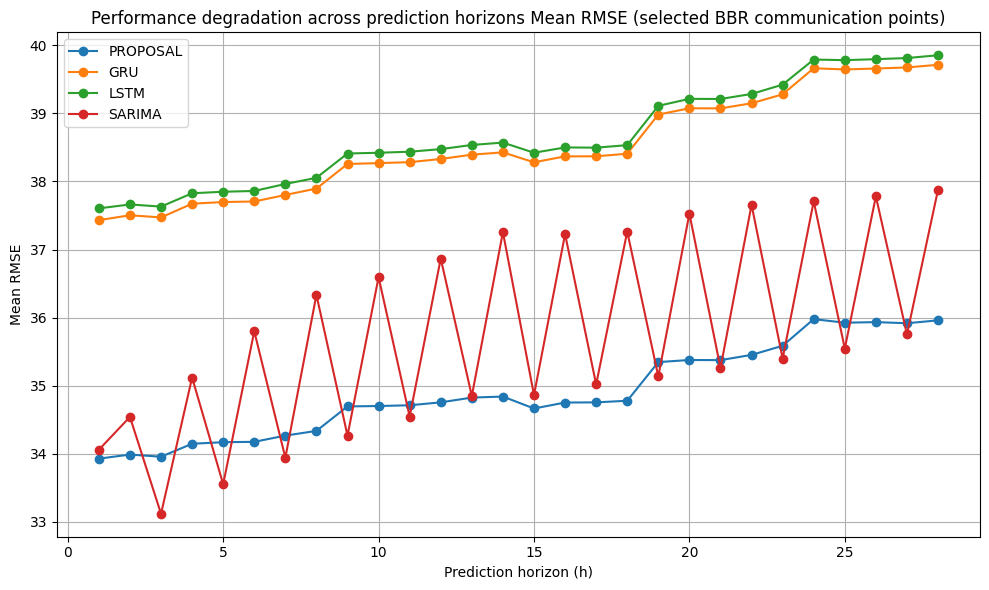

,model,horizon,mean_rmse
0,GRU,1,37.431279
1,GRU,2,37.503177
2,GRU,3,37.471324
3,GRU,4,37.673347
4,GRU,5,37.697646


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# =========================
# Config
# =========================
CSV_PATH = Path("./metrics/degradation_horizon_stress_selected_links.csv")
MODELS = ["PROPOSAL", "GRU", "LSTM", "SARIMA"]  # SARIMA se existir
OUTPUT_FIG = Path("./metrics/degradation_horizon_mean_rmse.png")

# =========================
# Load data
# =========================
df = pd.read_csv(CSV_PATH)

# Garantir tipos corretos
df["horizon"] = df["horizon"].astype(int)
df["rmse"] = df["rmse"].astype(float)

# =========================
# Agregação: RMSE médio por horizonte e modelo
# =========================
df_mean = (
    df.groupby(["model", "horizon"], as_index=False)
      .agg(mean_rmse=("rmse", "mean"))
)

# =========================
# Plot
# =========================
plt.figure(figsize=(10, 6))

for model in MODELS:
    if model in df_mean["model"].values:
        g = df_mean[df_mean["model"] == model]
        plt.plot(g["horizon"], g["mean_rmse"], marker="o", label=model)

plt.xlabel("Prediction horizon (h)")
plt.ylabel("Mean RMSE")
plt.title("Performance degradation across prediction horizons Mean RMSE (selected BBR communication points)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Salvar figura
plt.savefig(OUTPUT_FIG, dpi=150)
plt.show()

df_mean.head()


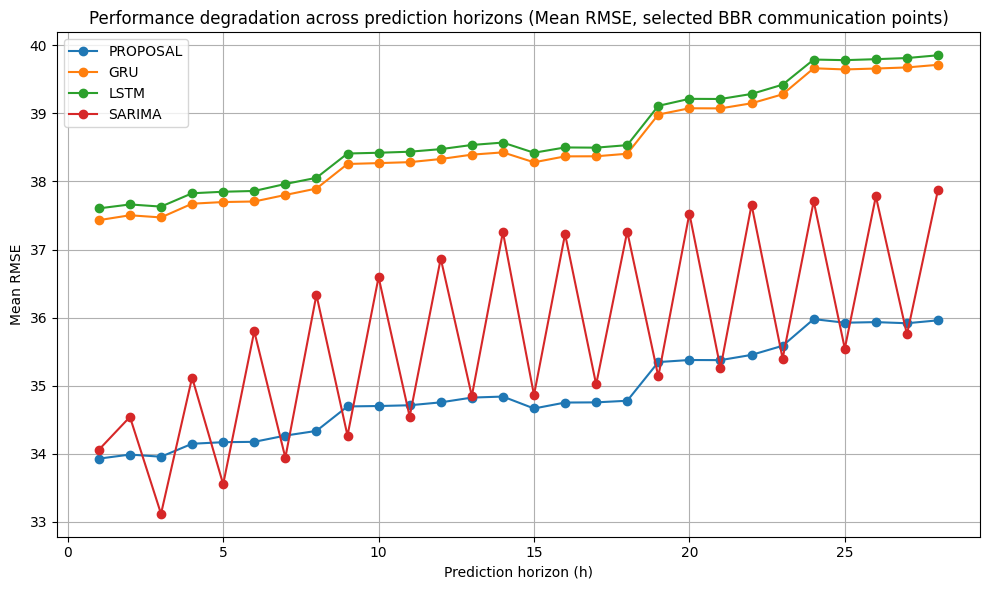

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Load
# =========================
csv_path = "./metrics/degradation_horizon_stress_selected_links.csv"
df = pd.read_csv(csv_path)

df["horizon"] = df["horizon"].astype(int)
df["rmse"] = df["rmse"].astype(float)

# =========================
# Média por horizonte/modelo
# =========================
df_mean = (
    df.groupby(["model", "horizon"], as_index=False)
      .agg(mean_rmse=("rmse", "mean"))
)

# =========================
# Plot
# =========================
plt.figure(figsize=(10, 6))

for model in ["PROPOSAL", "GRU", "LSTM", "SARIMA"]:
    if model in df_mean["model"].unique():
        g = df_mean[df_mean["model"] == model]
        plt.plot(g["horizon"], g["mean_rmse"], marker="o", label=model)

plt.xlabel("Prediction horizon (h)")
plt.ylabel("Mean RMSE")
plt.title("Performance degradation across prediction horizons (Mean RMSE, selected BBR communication points)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [3]:
H_MAX = df["horizon"].max()

summary = []

for model, g in df_mean.groupby("model"):
    rmse_h1 = g.loc[g["horizon"] == 1, "mean_rmse"].values
    rmse_hH = g.loc[g["horizon"] == H_MAX, "mean_rmse"].values

    if len(rmse_h1) == 0 or len(rmse_hH) == 0:
        continue

    rmse_h1 = rmse_h1[0]
    rmse_hH = rmse_hH[0]

    summary.append({
        "model": model,
        "rmse_h1": rmse_h1,
        "rmse_hH": rmse_hH,
        "delta_rmse": rmse_hH - rmse_h1,
        "relative_degradation": (rmse_hH - rmse_h1) / rmse_h1
    })

df_summary = pd.DataFrame(summary).sort_values("relative_degradation")
df_summary


,model,rmse_h1,rmse_hH,delta_rmse,relative_degradation
1,LSTM,37.604484,39.854778,2.250294,0.059841
2,PROPOSAL,33.926224,35.959137,2.032913,0.059922
0,GRU,37.431279,39.714563,2.283284,0.060999
3,SARIMA,34.056727,37.879669,3.822942,0.112252


In [4]:
import numpy as np

slopes = []

for model, g in df_mean.groupby("model"):
    slope = np.polyfit(g["horizon"], g["mean_rmse"], 1)[0]
    slopes.append({"model": model, "rmse_slope": slope})

pd.DataFrame(slopes)


,model,rmse_slope
0,GRU,0.088578
1,LSTM,0.087415
2,PROPOSAL,0.079109
3,SARIMA,0.109742
